# 07 · Figures: all plots in one place, one style

This notebook **only reads saved results** (`results/tables/`, `data/processed/`) and redraws every figure. No permutation test, bootstrap or model is re-run, so the whole notebook takes seconds.

**How to use**

1. Run notebooks 01–06 once (or whenever the data or the analysis change).
2. Change colours, fonts, sizes and output format in the **STYLE** cell below.
3. Change axes, titles or which categories are shown in the small `# --- edit here ---` block at the top of each figure cell.
4. Re-run only this notebook. Figures are saved to `results/figures/final/`; the figures written by notebooks 01–06 are never overwritten.

PCA, dendrograms and the proteomaps are recomputed here from the saved matrix: these are fast, deterministic calculations, not statistical tests.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yml").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from proteome_alloc import config, scope, annotation, allocation, asca, combined, proteomap
from proteome_alloc.ingest import GROWTH

cfg = config.load_config()
print("Repository root:", cfg.root)

Repository root: C:\Users\arlin\OneDrive\Documentos\proteome_allocation\proteome_allocation


## STYLE: the only place to change colours, fonts and output

Every figure below reads these values, so one change here harmonises all figures.

In [54]:
# ======================= EDIT HERE ==================================================================
STYLE = {
    # identity of each study: colour, marker and the name shown in legends (also sets legend order)
       "dataset_colour": {"schmidt_2016": "#1f9a6a", "mori_2021": "#8bc34a", "wu_2023": "#a77be6", "zhu_2025": "#5a3dc8"},
    "dataset_marker": {"schmidt_2016": "o", "mori_2021": "o", "wu_2023": "o", "zhu_2025": "o"},
    "dataset_label":  {"schmidt_2016": "DF01", "mori_2021": "DF02", "wu_2023": "DF03", "zhu_2025": "DF04"},
    # direction of an effect (forest plot, bars, heat-map ends)
    "up": "#2a37f0",          # increases with growth rate
    "down": "#f5304a",        # decreases with growth r ate
    "neutral": "#a1a1a0",     # not significant / excluded
    # extra series colours (e.g. the four sensitivity scenarios) 
    "series": ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6"],
    # colour maps: None = built from the colours above; or any matplotlib name, e.g. "RdBu", "viridis"
    "diverging_cmap": None,
    
    "sequential_cmap": None,
    # text and marks
    "font": "DejaVu Sans",
    "font_size": 10, "title_size": 11, "label_size": 10, "tick_size": 9, "legend_size": 9,
    "marker_size": 45, "line_width": 2.0, "edge_colour": "#0b0b0b",
    "background": "white", "grid": True, "grid_colour": "#e1e0d9",
    # output
    "format": "png",          # "png", "svg" or "pdf" (svg/pdf stay sharp when enlarged in slides)
    "dpi": 300,
    "folder": "final",        # results/figures/<folder>/
}
GROWTH_LABEL = "Growth rate (h$^{-1}$)"
# =====================================================================================================


def apply_style():
    plt.rcParams.update({
        "font.family": STYLE["font"], "font.size": STYLE["font_size"],
        "axes.titlesize": STYLE["title_size"], "axes.labelsize": STYLE["label_size"],
        "xtick.labelsize": STYLE["tick_size"], "ytick.labelsize": STYLE["tick_size"],
        "legend.fontsize": STYLE["legend_size"], "legend.frameon": False,
        "figure.facecolor": STYLE["background"], "axes.facecolor": STYLE["background"],
        "savefig.facecolor": STYLE["background"],
        "axes.grid": STYLE["grid"], "grid.color": STYLE["grid_colour"], "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
        "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 16,
    })


apply_style()
OUT = cfg.figures / STYLE["folder"]
OUT.mkdir(parents=True, exist_ok=True)


def colour(d):  return STYLE["dataset_colour"].get(d, STYLE["neutral"])
def marker(d):  return STYLE["dataset_marker"].get(d, "X")
def label(d):   return STYLE["dataset_label"].get(d, d)


def study_order(values):
    # studies in the order of STYLE["dataset_label"], then any others
    present = list(pd.unique(np.asarray(values)))
    return [d for d in STYLE["dataset_label"] if d in present] + [d for d in present if d not in STYLE["dataset_label"]]


def scatter_datasets(ax, x, y, datasets, **kwargs):
    # one scatter per study with its colour, marker and legend name
    x, y, datasets = np.asarray(x), np.asarray(y), np.asarray(datasets)
    for d in study_order(datasets):
        m = datasets == d
        ax.scatter(x[m], y[m], s=STYLE["marker_size"], color=colour(d), marker=marker(d),
                   edgecolor=STYLE["edge_colour"], linewidth=0.5, label=label(d), zorder=3, **kwargs)


def diverging_cmap():
    if STYLE["diverging_cmap"]:
        return STYLE["diverging_cmap"]
    return LinearSegmentedColormap.from_list("updown", [STYLE["down"], "#f4f3ef", STYLE["up"]])


def sequential_cmap():
    if STYLE["sequential_cmap"]:
        return STYLE["sequential_cmap"]
    return LinearSegmentedColormap.from_list("seq", ["#e8f0fb", STYLE["up"], "#0d2a52"])


def save(fig, name):
    path = OUT / f"{name}.{STYLE['format']}"
    fig.savefig(path, dpi=STYLE["dpi"], bbox_inches="tight")
    print("saved:", path.relative_to(cfg.root))


# make the proteomap module use the same direction colours
proteomap.UP, proteomap.DOWN = STYLE["up"], STYLE["down"]

## Load saved results (nothing is recomputed)

In [19]:
def read(name):
    path = cfg.tables / f"{name}.tsv"
    if not path.exists():
        print(f"missing: {path.name} - run the notebook that writes it first")
        return None
    return pd.read_csv(path, sep="\t", index_col=0)


slopes      = read("03_cog_growth_slopes")
fractions   = read("03_cog_fractions_per_condition")
combined_f  = read("03_cog_fractions_combined_display")
conditions  = read("03_condition_table")
variance    = read("04_asca_variance_partition")
proteins    = read("04_asca_protein_slopes")
asca_scores = read("04_asca_condition_scores")
predictions = read("05_predictions")
sensitivity = read("06_sensitivity_slopes")
null_asca   = read("04_asca_null_distribution")      # optional (see the last section)
null_pls    = read("05_prediction_null_rmse")        # optional

conditions["batch"] = [c.split("|", 1)[0] for c in conditions.index]
X, obs, var = scope.load_scoped(cfg)
in_scope = obs.index[obs["In_Scope"]]
annotation_table = annotation.load_annotation(cfg)
labels = annotation.category_labels(cfg)
print(f"{len(conditions)} conditions, {slopes['tested'].sum()} tested COG categories, {len(in_scope)} in-scope runs")

missing: 04_asca_null_distribution.tsv - run the notebook that writes it first
missing: 05_prediction_null_rmse.tsv - run the notebook that writes it first
28 conditions, 21 tested COG categories, 36 in-scope runs


## F1 · Growth-rate coverage per study (design)

saved: results\figures\final\F01_design_growth_coverage.png


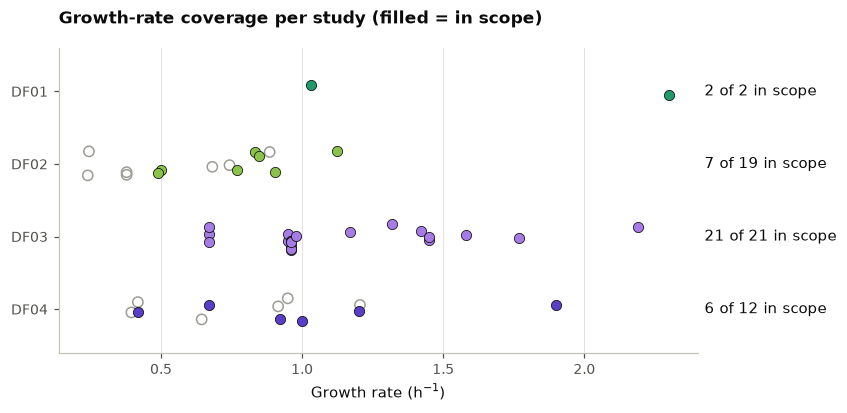

In [20]:
# --- edit here ---
FIGSIZE = (7.5, 3.6)
XLIM = None                     # e.g. (0, 2.5)
TITLE = "Growth-rate coverage per study (filled = in scope)"
# ------------------
fig, ax = plt.subplots(figsize=FIGSIZE)
rng = np.random.default_rng(0)                                  # vertical jitter for display only
studies = study_order(obs["Dataset_Source"])
for row, d in enumerate(studies):
    sub = obs[(obs["Dataset_Source"] == d) & obs[GROWTH].notna()]
    y = row + rng.uniform(-0.18, 0.18, len(sub))
    inside = sub["In_Scope"].to_numpy(bool)
    ax.scatter(sub[GROWTH][inside], y[inside], s=STYLE["marker_size"], color=colour(d), marker=marker(d),
               edgecolor=STYLE["edge_colour"], linewidth=0.5, zorder=3)
    ax.scatter(sub[GROWTH][~inside], y[~inside], s=STYLE["marker_size"], facecolors="none",
               edgecolors=STYLE["neutral"], marker=marker(d), zorder=2)
    n_in, n_all = int(obs.loc[obs["Dataset_Source"] == d, "In_Scope"].sum()), int((obs["Dataset_Source"] == d).sum())
    ax.text(1.01, row, f"{n_in} of {n_all} in scope", transform=ax.get_yaxis_transform(), va="center")
ax.set_yticks(range(len(studies)), [label(d) for d in studies])
ax.set_ylim(-0.6, len(studies) - 0.4); ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel(GROWTH_LABEL); ax.set_title(TITLE)
if XLIM: ax.set_xlim(XLIM)
save(fig, "F01_design_growth_coverage"); plt.show()

## F2 · Distribution of quantified mass fractions per sample

saved: results\figures\final\F02_mass_fraction_distributions.png


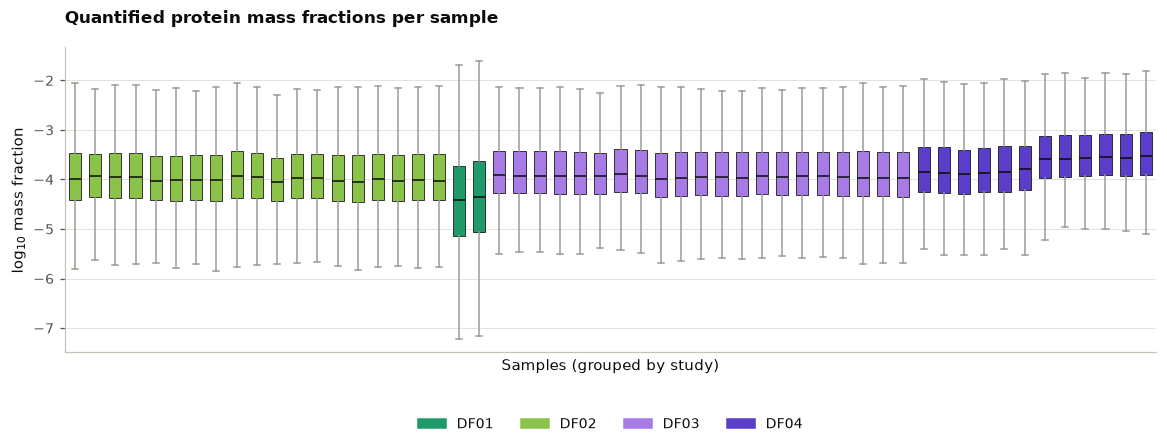

In [22]:
# --- edit here ---
FIGSIZE = None                  # None = automatic width
YLIM = None                     # e.g. (-8, -1)
TITLE = "Quantified protein mass fractions per sample"
# ------------------
order = obs.sort_values("Dataset_Source", kind="stable").index
fig, ax = plt.subplots(figsize=FIGSIZE or (max(7.5, 0.2 * len(order) + 2), 3.6))
data = [np.log10(X.loc[s][X.loc[s] > 0].to_numpy(float)) for s in order]
boxes = ax.boxplot(data, widths=0.6, patch_artist=True, showfliers=False,
                   medianprops={"color": STYLE["edge_colour"]}, whiskerprops={"color": STYLE["neutral"]},
                   capprops={"color": STYLE["neutral"]})
for patch, s in zip(boxes["boxes"], order):
    patch.set(facecolor=colour(obs.loc[s, "Dataset_Source"]), edgecolor=STYLE["edge_colour"], linewidth=0.5)
handles = [plt.Rectangle((0, 0), 1, 1, color=colour(d)) for d in study_order(obs["Dataset_Source"])]
ax.legend(handles, [label(d) for d in study_order(obs["Dataset_Source"])], ncol=4, loc="lower center",
          bbox_to_anchor=(0.5, -0.3))
ax.set_xticks([]); ax.grid(axis="x", visible=False)
ax.set_xlabel("Samples (grouped by study)"); ax.set_ylabel("log$_{10}$ mass fraction"); ax.set_title(TITLE)
if YLIM: ax.set_ylim(YLIM)
save(fig, "F02_mass_fraction_distributions"); plt.show()

## F3 · Missingness: detection state and left-censoring

saved: results\figures\final\F03_missingness.png


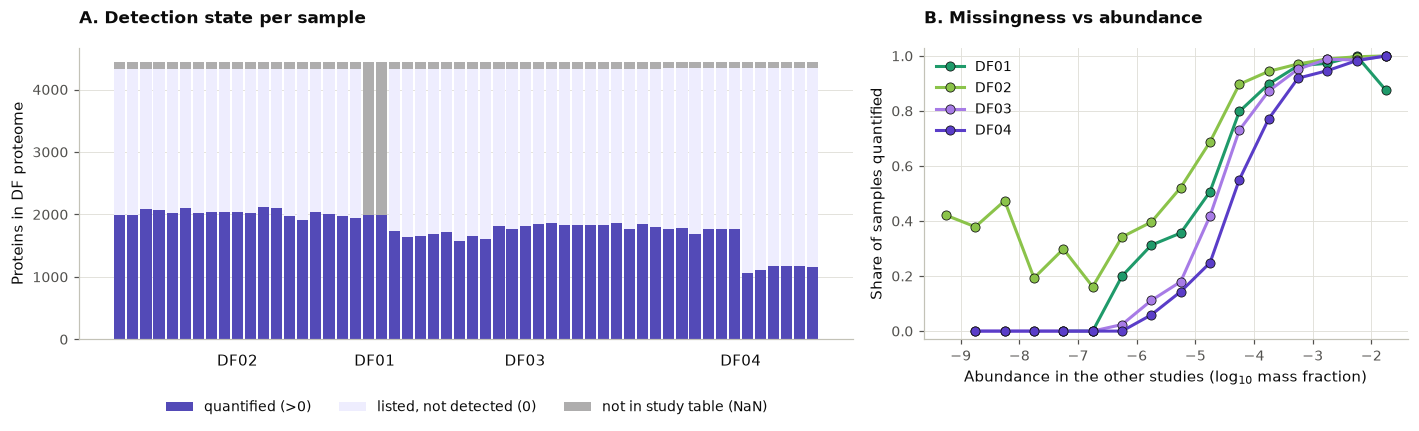

In [27]:
# --- edit here ---
FIGSIZE = (13, 4.2)
BIN = 0.5                       # width of abundance bins (log10 units)
# ------------------
order = obs.sort_values("Dataset_Source", kind="stable").index
studies = study_order(obs["Dataset_Source"])
state = pd.DataFrame({"quantified (>0)": (X > 0).sum(axis=1),
                      "listed, not detected (0)": (X == 0).sum(axis=1),
                      "not in study table (NaN)": X.isna().sum(axis=1)}).loc[order]
fig, (left, right) = plt.subplots(1, 2, figsize=FIGSIZE, gridspec_kw={"width_ratios": [1.6, 1]})
bottom = np.zeros(len(state))
for column, c in zip(state.columns, [STYLE["up"], STYLE["down"], "#aeadad"]):
    left.bar(range(len(state)), state[column], bottom=bottom, color=c, width=0.85, label=column)
    bottom += state[column].to_numpy()
for d in studies:
    idx = np.flatnonzero(obs.loc[order, "Dataset_Source"].to_numpy() == d)
    left.text(idx.mean(), -0.05, label(d), transform=left.get_xaxis_transform(), ha="center", va="top")
left.set_xticks([]); left.grid(axis="x", visible=False)
left.set_ylabel("Proteins in DF proteome"); left.set_title("A. Detection state per sample")
left.legend(loc="lower center", bbox_to_anchor=(0.5, -0.3), ncol=3)
log_q = np.log10(X.where(X > 0))
for d in studies:
    inside = obs["Dataset_Source"] == d
    reference = log_q.loc[~inside].mean()                       # abundance in the other studies
    detected = (X.loc[inside] > 0).mean()
    ok = reference.notna()
    curve = detected[ok].groupby(np.floor(reference[ok] / BIN) * BIN + BIN / 2).mean()
    right.plot(curve.index, curve.values, color=colour(d), marker=marker(d), markeredgecolor=STYLE["edge_colour"],
               markeredgewidth=0.5, linewidth=STYLE["line_width"], label=label(d))
right.set_ylim(-0.03, 1.03)
right.set_xlabel("Abundance in the other studies (log$_{10}$ mass fraction)")
right.set_ylabel("Share of samples quantified"); right.set_title("B. Missingness vs abundance")
right.legend()
fig.tight_layout()
save(fig, "F03_missingness"); plt.show()

## F4 · COG allocation per condition, all studies combined

saved: results\figures\final\F04_cog_allocation_heatmap.png


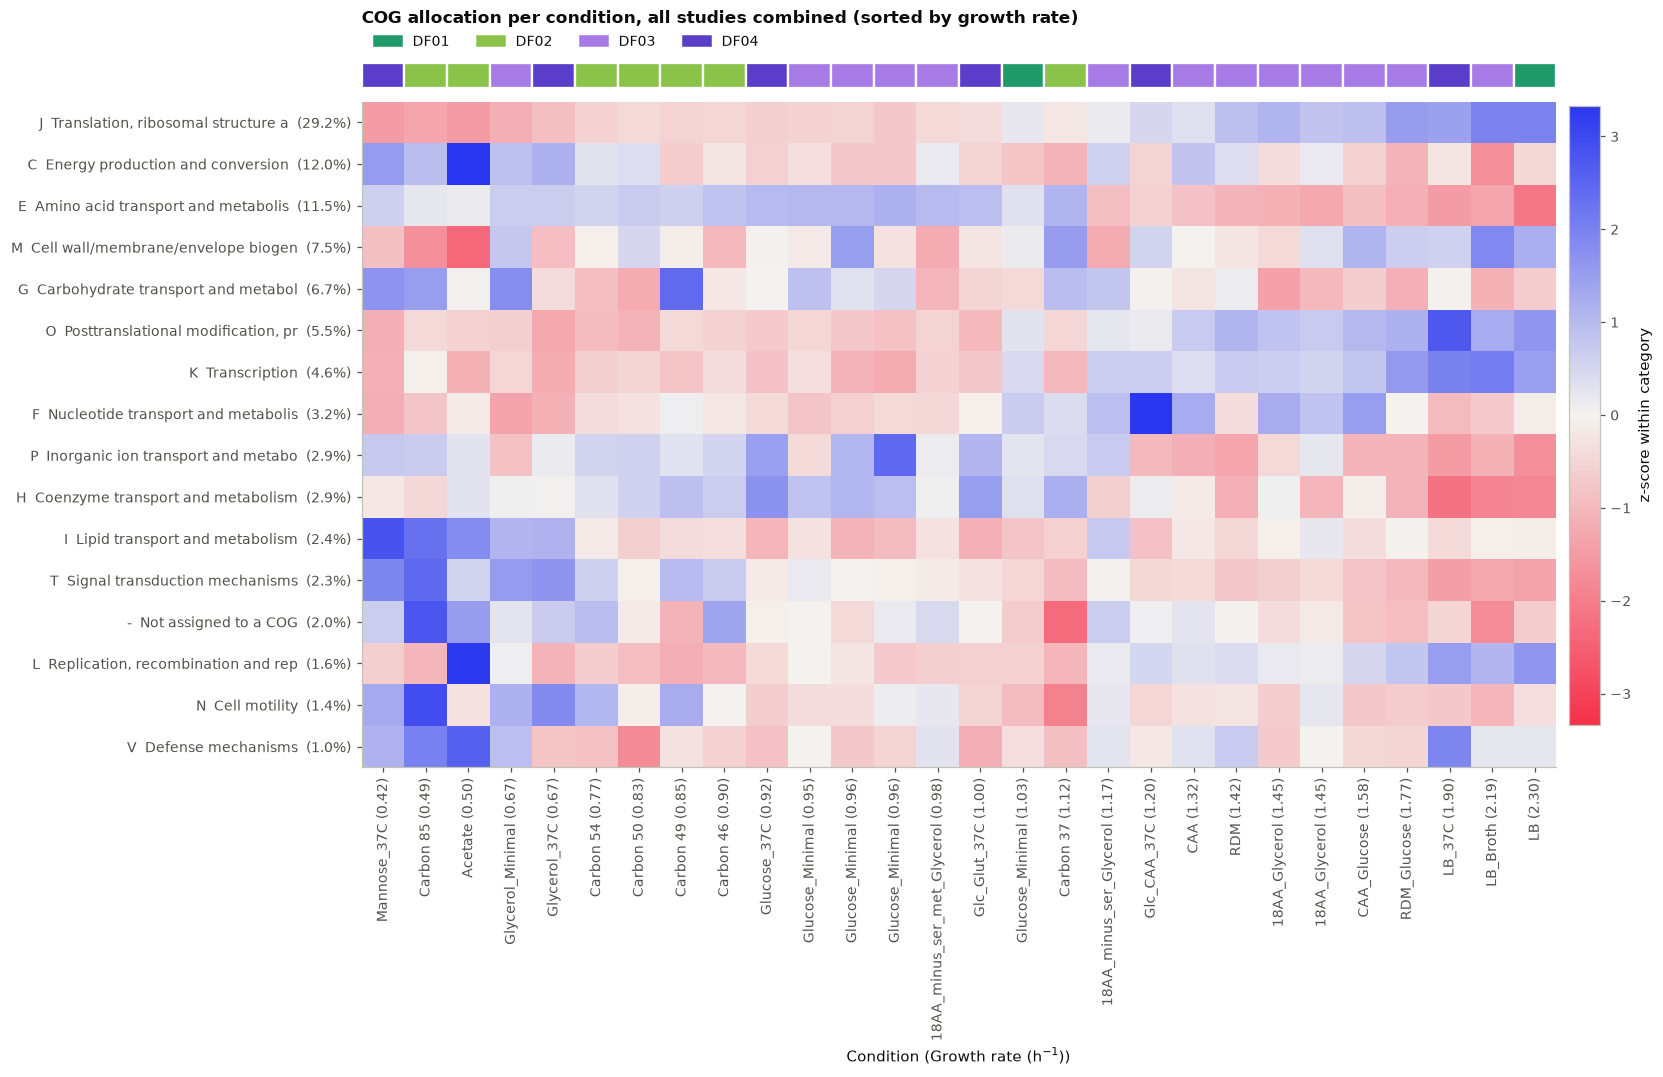

In [55]:
# --- edit here ---
FIGSIZE = None                  # None = automatic
MIN_SHARE = 0.001               # hide categories below 0.1 % of the proteome on average
TOP = 16                        # number of categories shown
TITLE = "COG allocation per condition, all studies combined (sorted by growth rate)"
# ------------------
order = conditions.sort_values(GROWTH).index
means = combined_f.mean()
cats = means[means >= MIN_SHARE].sort_values(ascending=False).index[:TOP]
values = combined_f.loc[order, cats]
z = ((values - values.mean()) / values.std(ddof=1)).T.fillna(0)
limit = float(np.abs(z.to_numpy()).max()) or 1.0
fig, (strip, ax) = plt.subplots(2, 1, figsize=FIGSIZE or (0.34 * len(order) + 5, 0.32 * len(cats) + 3.2),
                                sharex=True, gridspec_kw={"height_ratios": [0.6, len(cats)], "hspace": 0.04})
for i, d in enumerate(conditions.loc[order, "Dataset_Source"]):
    strip.add_patch(plt.Rectangle((i - 0.5, 0), 1, 1, facecolor=colour(d), edgecolor="white", linewidth=1.5))
strip.set_xlim(-0.5, len(order) - 0.5); strip.set_ylim(0, 1); strip.axis("off")
present = study_order(conditions["Dataset_Source"])
strip.legend([plt.Rectangle((0, 0), 1, 1, color=colour(d)) for d in present], [label(d) for d in present],
             ncol=4, loc="lower left", bbox_to_anchor=(0, 1.05))
strip.set_title(TITLE, pad=26)
image = ax.imshow(z.to_numpy(), aspect="auto", cmap=diverging_cmap(), vmin=-limit, vmax=limit)
ax.set_yticks(range(len(cats)), [f"{c}  {labels.get(c, '')[:34]}  ({means[c] * 100:.1f}%)" for c in cats])
ax.set_xticks(range(len(order)), [f"{i.split('|', 1)[1]} ({conditions.loc[i, GROWTH]:.2f})" for i in order],
              rotation=90)
ax.grid(False); ax.set_xlabel("Condition (" + GROWTH_LABEL + ")")
fig.colorbar(image, ax=[strip, ax], label="z-score within category", fraction=0.025, pad=0.01)
save(fig, "F04_cog_allocation_heatmap"); plt.show()

## F5 · Growth-rate dependence of every COG category (forest plot)

saved: results\figures\final\F05_cog_slopes_forest.png


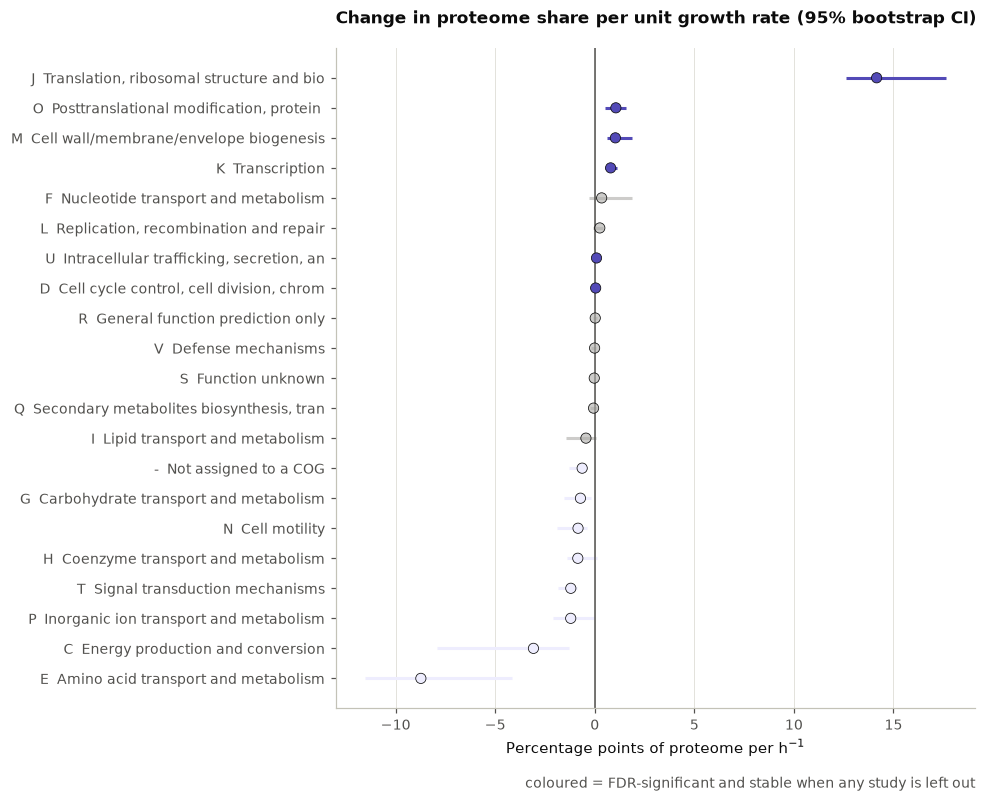

In [8]:
# --- edit here ---
FIGSIZE = None
XLIM = None                     # e.g. (-10, 16)
TITLE = "Change in proteome share per unit growth rate (95% bootstrap CI)"
# ------------------
data = slopes[slopes["tested"]].sort_values("slope_per_h-1")
est, low, high = (data[c].to_numpy() * 100 for c in ("slope_per_h-1", "ci_low", "ci_high"))
robust = (data["significant"] & data["sign_stable_leave_one_dataset_out"]).to_numpy(bool)
colours = [STYLE["up"] if (r and v > 0) else STYLE["down"] if r else STYLE["neutral"] for v, r in zip(est, robust)]
fig, ax = plt.subplots(figsize=FIGSIZE or (7.5, 0.3 * len(data) + 1.5))
y = np.arange(len(data))
ax.hlines(y, low, high, color=colours, linewidth=STYLE["line_width"], zorder=2)
ax.scatter(est, y, color=colours, s=STYLE["marker_size"], edgecolor=STYLE["edge_colour"], linewidth=0.5, zorder=3)
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_yticks(y, [f"{c}  {labels.get(c, '')[:40]}" for c in data.index])
ax.grid(axis="y", visible=False)
ax.set_xlabel("Percentage points of proteome per h$^{-1}$"); ax.set_title(TITLE)
ax.text(1.0, -0.12, "coloured = FDR-significant and stable when any study is left out", transform=ax.transAxes,
        ha="right", fontsize=STYLE["tick_size"], color="#52514e")
if XLIM: ax.set_xlim(XLIM)
save(fig, "F05_cog_slopes_forest"); plt.show()

## F6 · Growth laws, all studies combined (study offsets removed for display)

saved: results\figures\final\F06_growth_laws_combined.png


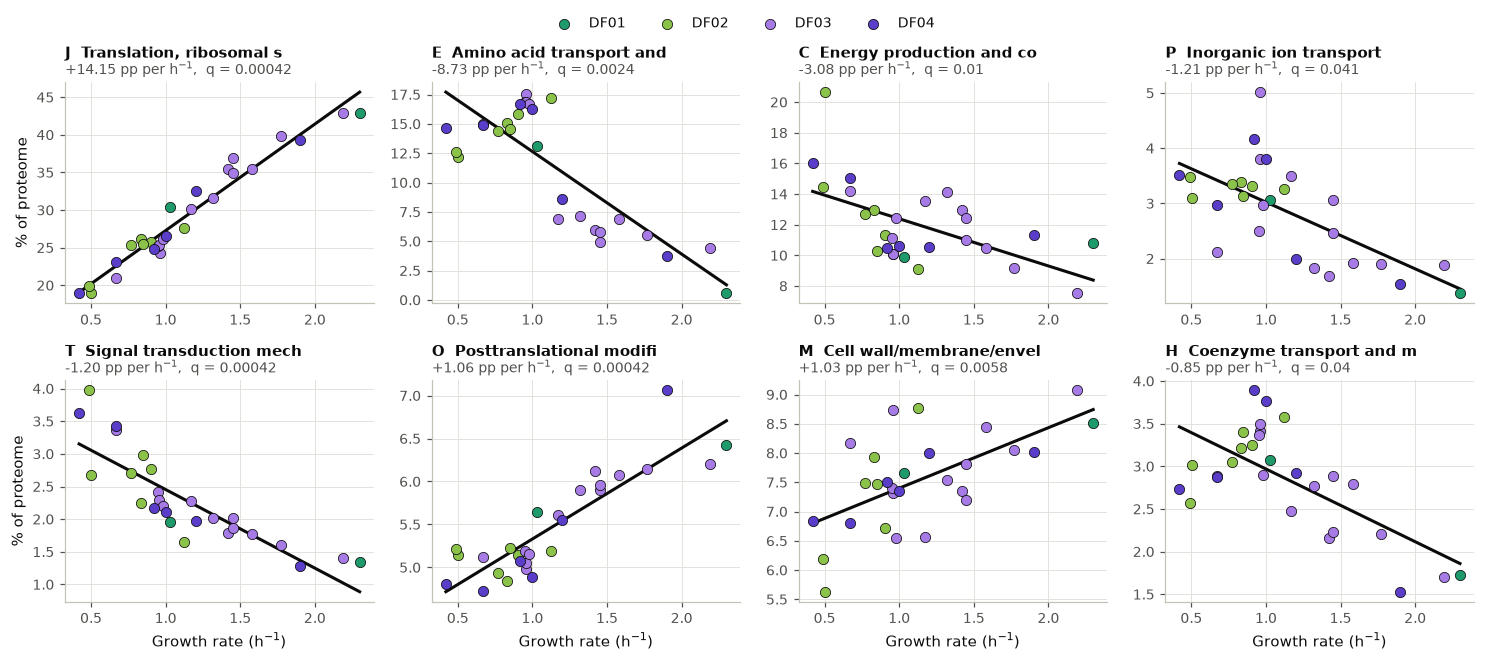

In [9]:
# --- edit here ---
CATEGORIES = None               # e.g. ["J", "E", "C", "G"]; None = the 8 largest tested effects
NCOLS = 4
PANEL = (3.4, 2.9)              # size of one panel (width, height)
NAME_CHARS = 24                 # characters of the category name shown in each panel title
# ------------------
tested = slopes[slopes["tested"]]
cats = CATEGORIES or list(tested["slope_per_h-1"].abs().sort_values(ascending=False).index[:8])
mu = conditions.loc[combined_f.index, GROWTH].to_numpy(float)
study = conditions.loc[combined_f.index, "Dataset_Source"].to_numpy()
rows = int(np.ceil(len(cats) / NCOLS))
fig, axes = plt.subplots(rows, NCOLS, figsize=(PANEL[0] * NCOLS, PANEL[1] * rows), squeeze=False)
xs = np.array([mu.min(), mu.max()])
for ax, c in zip(axes.ravel(), cats):
    y = combined_f[c].to_numpy(float) * 100
    s = slopes.loc[c, "slope_per_h-1"] * 100
    ax.plot(xs, y.mean() + s * (xs - mu.mean()), color=STYLE["edge_colour"], linewidth=STYLE["line_width"], zorder=2)
    scatter_datasets(ax, mu, y, study)
    ax.set_title(f"{c}  {labels.get(c, '')[:NAME_CHARS]}", fontsize=STYLE["title_size"] - 1)
    ax.text(0, 1.02, f"{s:+.2f} pp per h$^{{-1}}$,  q = {slopes.loc[c, 'q_BH']:.2g}", transform=ax.transAxes,
            fontsize=STYLE["tick_size"], color="#52514e", va="bottom")
for ax in axes.ravel()[len(cats):]:
    ax.axis("off")
for ax in axes[-1]:
    ax.set_xlabel(GROWTH_LABEL)
for ax in axes[:, 0]:
    ax.set_ylabel("% of proteome")
handles, names = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, names, loc="upper center", ncol=len(names), bbox_to_anchor=(0.5, 1.04))
fig.tight_layout()
save(fig, "F06_growth_laws_combined"); plt.show()

## F7 · Growth laws per batch (what the model sees: shared slope, own baseline)

saved: results\figures\final\F07_growth_laws_per_batch.png


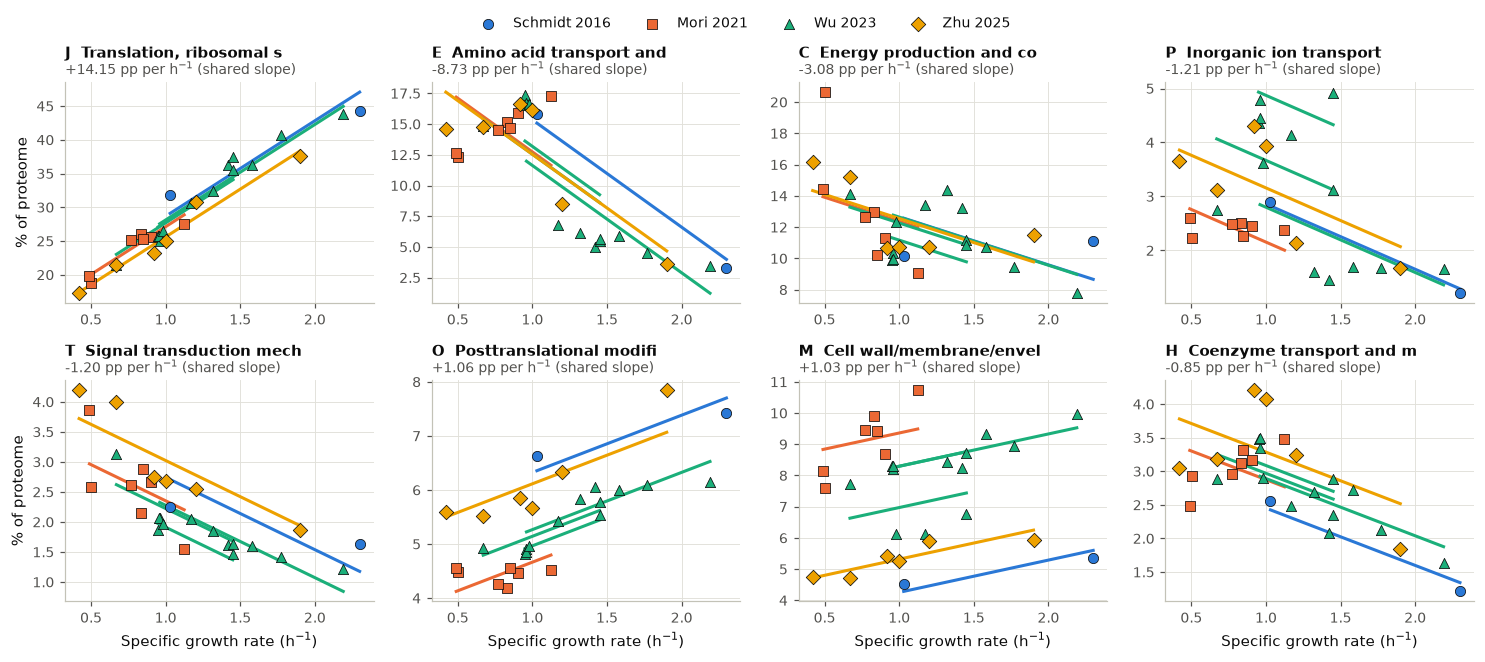

In [10]:
# --- edit here ---
CATEGORIES = None               # same rule as F6
NCOLS = 4
PANEL = (3.4, 2.9)
NAME_CHARS = 24
# ------------------
tested = slopes[slopes["tested"]]
cats = CATEGORIES or list(tested["slope_per_h-1"].abs().sort_values(ascending=False).index[:8])
mu = conditions.loc[fractions.index, GROWTH].to_numpy(float)
study = conditions.loc[fractions.index, "Dataset_Source"].to_numpy()
batch = conditions.loc[fractions.index, "batch"].to_numpy()
rows = int(np.ceil(len(cats) / NCOLS))
fig, axes = plt.subplots(rows, NCOLS, figsize=(PANEL[0] * NCOLS, PANEL[1] * rows), squeeze=False)
for ax, c in zip(axes.ravel(), cats):
    y = fractions[c].to_numpy(float) * 100
    s = slopes.loc[c, "slope_per_h-1"] * 100
    for b in pd.unique(batch):
        m = batch == b
        xs = np.array([mu[m].min(), mu[m].max()])
        ax.plot(xs, y[m].mean() + s * (xs - mu[m].mean()), color=colour(study[m][0]),
                linewidth=STYLE["line_width"], zorder=2)
    scatter_datasets(ax, mu, y, study)
    ax.set_title(f"{c}  {labels.get(c, '')[:NAME_CHARS]}", fontsize=STYLE["title_size"] - 1)
    ax.text(0, 1.02, f"{s:+.2f} pp per h$^{{-1}}$ (shared slope)", transform=ax.transAxes,
            fontsize=STYLE["tick_size"], color="#52514e", va="bottom")
for ax in axes.ravel()[len(cats):]:
    ax.axis("off")
for ax in axes[-1]:
    ax.set_xlabel(GROWTH_LABEL)
for ax in axes[:, 0]:
    ax.set_ylabel("% of proteome")
handles, names = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, names, loc="upper center", ncol=len(names), bbox_to_anchor=(0.5, 1.04))
fig.tight_layout()
save(fig, "F07_growth_laws_per_batch"); plt.show()

## F8 · Proteome maps of two contrasting conditions

saved: results\figures\final\F08_proteomaps.png


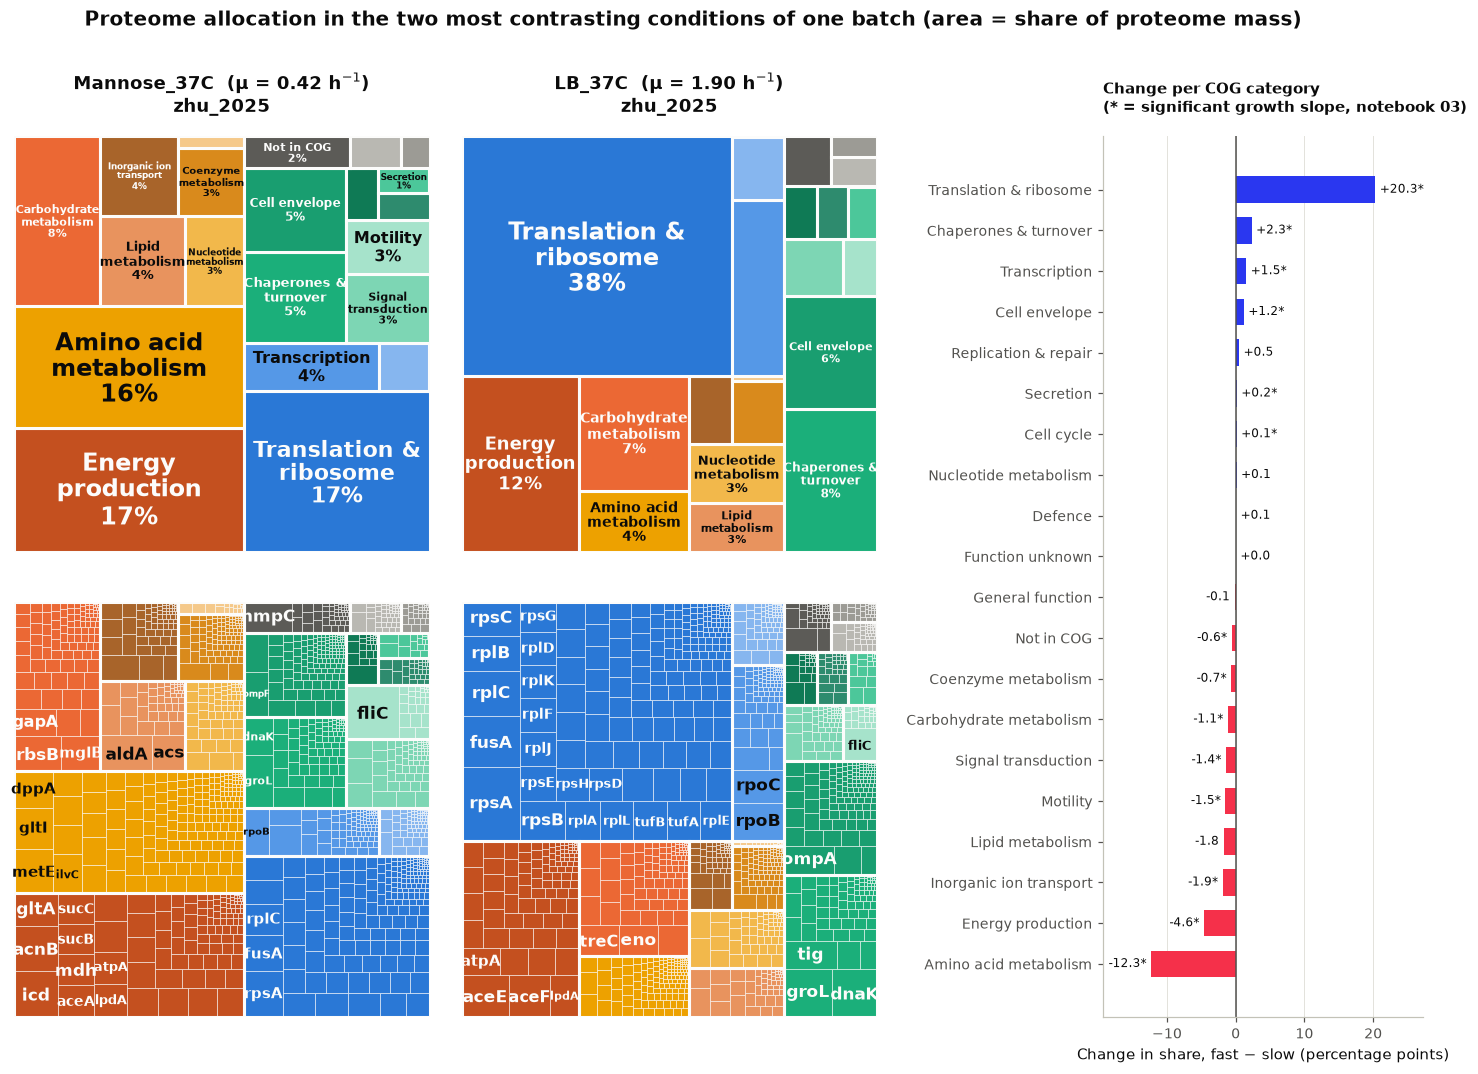

In [57]:
# --- edit here ---
MAP_CONDITIONS = None           # None = setting in config.yml; or e.g. ["wu_2023|Glycerol_Minimal", "wu_2023|LB_Broth"]
# proteomap.COLOURS.update({"J": "#2a78d6", "E": "#eda100"})   # optional: change COG category colours
# ------------------
profiles, pinfo = proteomap.condition_profiles(X.loc[in_scope], obs.loc[in_scope], cfg)
category = proteomap.primary_category(annotation_table, profiles.columns)
chosen = MAP_CONDITIONS or proteomap.select_conditions(pinfo, cfg)
change = proteomap.category_change(profiles, category, chosen)
fig = proteomap.plot_proteomaps(profiles, pinfo, category, chosen, gene_names=var["Gene_Name"], change=change,
                                significant=slopes["significant"] & slopes["sign_stable_leave_one_dataset_out"],
                                path=None, label_min_share=cfg["proteomap"]["label_min_share"])
save(fig, "F08_proteomaps"); plt.show()

## F9 · PCA before and after removing study offsets

saved: results\figures\final\F09_pca_before_after.png


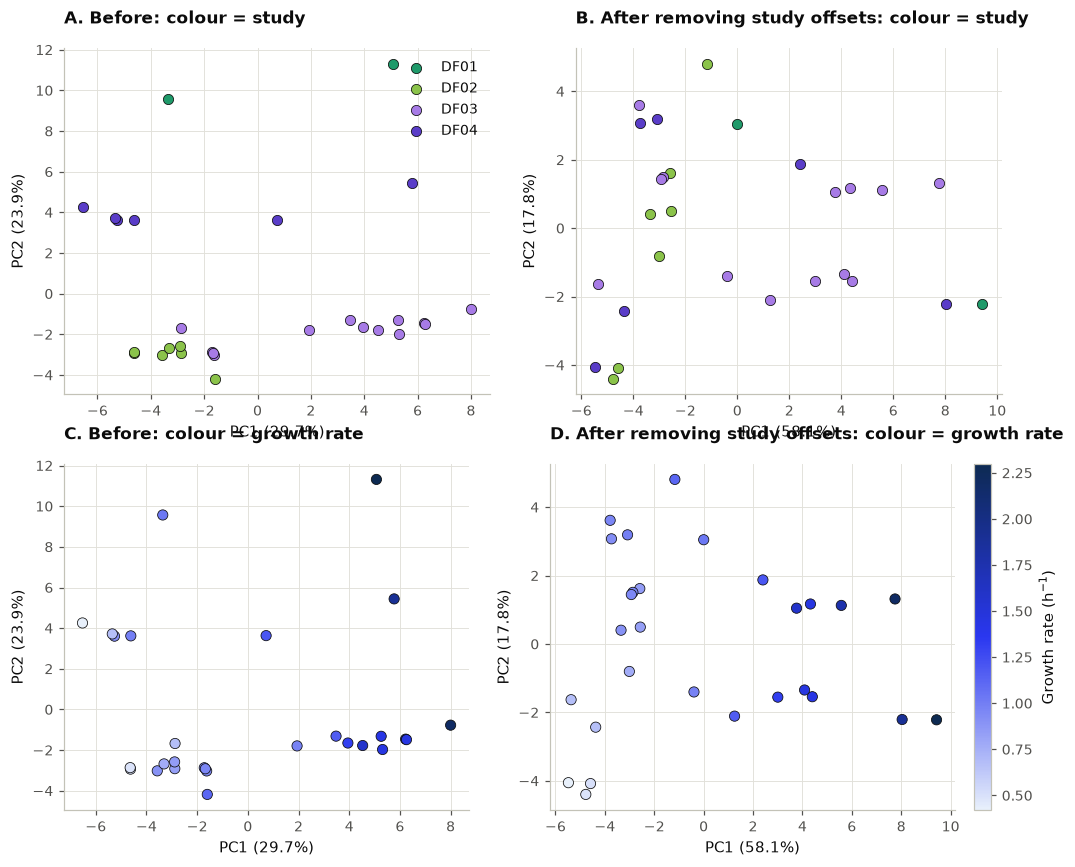

In [56]:
# --- edit here ---
FIGSIZE = (11, 9)
# ------------------
batch_key = cfg["allocation"]["batch_key"]
L, _ = asca.prepare_protein_matrix(X.loc[in_scope], obs.loc[in_scope], cfg)        # same matrix as notebook 04
Lc, linfo = allocation.aggregate_conditions(L, obs.loc[in_scope], cfg)
L_after = combined.remove_batch_effect(Lc, linfo, batch_key)
score_b, ratio_b = combined.pca_scores(Lc, orient=linfo[GROWTH])
score_a, ratio_a = combined.pca_scores(L_after, orient=linfo[GROWTH])
mu_p, st = linfo[GROWTH].to_numpy(float), linfo["Dataset_Source"].to_numpy()
fig, axes = plt.subplots(2, 2, figsize=FIGSIZE)
for col, (S, R, name) in enumerate([(score_b, ratio_b, "Before"), (score_a, ratio_a, "After removing study offsets")]):
    scatter_datasets(axes[0, col], S["PC1"], S["PC2"], st)
    axes[0, col].set_title(f"{'AB'[col]}. {name}: colour = study")
    for d in study_order(st):
        m = st == d
        sc = axes[1, col].scatter(S["PC1"][m], S["PC2"][m], c=mu_p[m], cmap=sequential_cmap(), vmin=mu_p.min(),
                                  vmax=mu_p.max(), marker=marker(d), s=STYLE["marker_size"],
                                  edgecolor=STYLE["edge_colour"], linewidth=0.5)
    axes[1, col].set_title(f"{'CD'[col]}. {name}: colour = growth rate")
    for row in (0, 1):
        axes[row, col].set_xlabel(f"PC1 ({R[0]:.1%})"); axes[row, col].set_ylabel(f"PC2 ({R[1]:.1%})")
axes[0, 0].legend()
fig.colorbar(sc, ax=axes[1, :], label=GROWTH_LABEL, fraction=0.03, pad=0.02)
save(fig, "F09_pca_before_after"); plt.show()

saved: results\figures\final\F09_pca_before_after.png


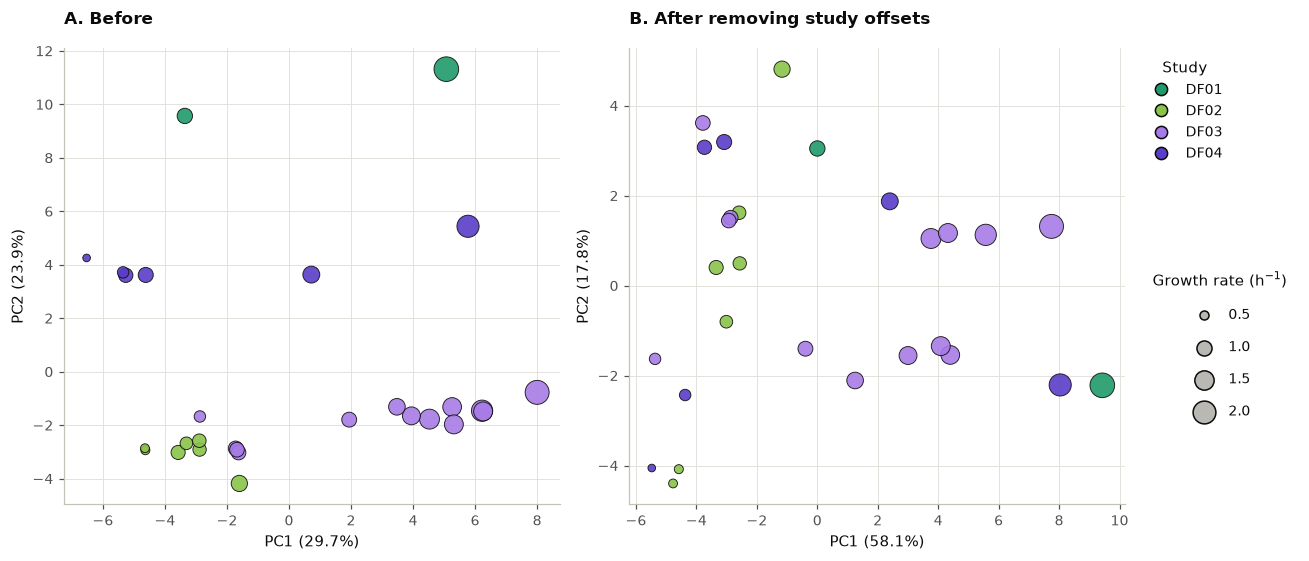

In [59]:
# --- edit here ---
FIGSIZE = (12, 5.2)
SIZE_RANGE = (25, 260)          # marker area (pt²) for the slowest and the fastest condition
SIZE_LEGEND = [0.5, 1.0, 1.5, 2.0]   # growth rates shown in the size legend (h-1)
# ------------------
batch_key = cfg["allocation"]["batch_key"]
L, _ = asca.prepare_protein_matrix(X.loc[in_scope], obs.loc[in_scope], cfg)        # same matrix as notebook 04
Lc, linfo = allocation.aggregate_conditions(L, obs.loc[in_scope], cfg)
L_after = combined.remove_batch_effect(Lc, linfo, batch_key)
score_b, ratio_b = combined.pca_scores(Lc, orient=linfo[GROWTH])
score_a, ratio_a = combined.pca_scores(L_after, orient=linfo[GROWTH])
mu_p, st = linfo[GROWTH].to_numpy(float), linfo["Dataset_Source"].to_numpy()

lo, hi = np.nanmin(mu_p), np.nanmax(mu_p)
def size_of(mu):                                                   # marker AREA proportional to growth rate
    return SIZE_RANGE[0] + (np.asarray(mu, float) - lo) / (hi - lo) * (SIZE_RANGE[1] - SIZE_RANGE[0])

fig, axes = plt.subplots(1, 2, figsize=FIGSIZE)
for ax, (S, R, name) in zip(axes, [(score_b, ratio_b, "A. Before"), (score_a, ratio_a, "B. After removing study offsets")]):
    for d in study_order(st):
        m = st == d
        ax.scatter(np.asarray(S["PC1"])[m], np.asarray(S["PC2"])[m], s=size_of(mu_p[m]), color=colour(d),
                   marker=marker(d), edgecolor=STYLE["edge_colour"], linewidth=0.6, alpha=0.9, zorder=3)
    ax.set_title(f"{name}")
    ax.set_xlabel(f"PC1 ({R[0]:.1%})"); ax.set_ylabel(f"PC2 ({R[1]:.1%})")

# legend 1: study colour (all markers the same size)
study_handles = [plt.Line2D([], [], linestyle="", marker=marker(d), markersize=8, markerfacecolor=colour(d),
                            markeredgecolor=STYLE["edge_colour"]) for d in study_order(st)]
first = axes[1].legend(study_handles, [label(d) for d in study_order(st)], title="Study",
                       loc="upper left", bbox_to_anchor=(1.02, 1.0), frameon=False)
axes[1].add_artist(first)
# legend 2: marker size = growth rate
shown = [v for v in SIZE_LEGEND if lo <= v <= hi] or [lo, hi]
size_handles = [plt.scatter([], [], s=size_of(v), color="#b9b8b2", edgecolor=STYLE["edge_colour"]) for v in shown]
axes[1].legend(size_handles, [f"{v:.1f}" for v in shown], title="Growth rate (h$^{-1}$)",
               loc="upper left", bbox_to_anchor=(1.02, 0.55), frameon=False, labelspacing=1.3, borderpad=0.8)
fig.tight_layout()
save(fig, "F09_pca_before_after"); plt.show()

## F10 · Clustering of conditions before and after removing study offsets

saved: results\figures\final\F10_condition_dendrograms.png


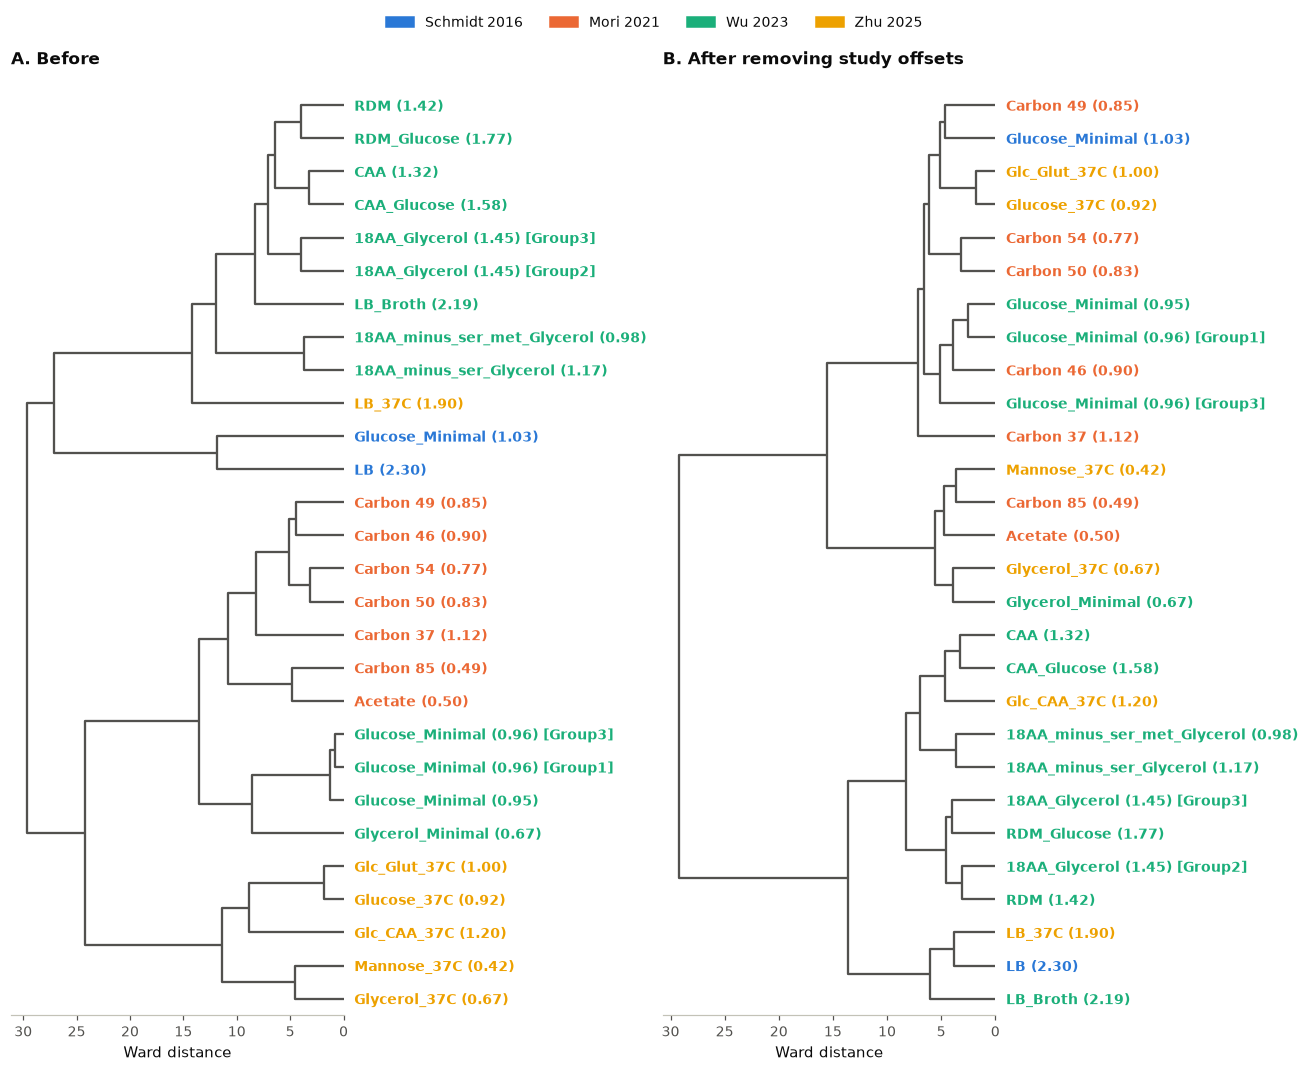

In [13]:
# --- edit here ---
FIGSIZE = None
# ------------------
from scipy.cluster.hierarchy import dendrogram, linkage
names = combined.condition_labels(linfo)
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE or (12, 0.26 * len(Lc) + 2.2))
for ax, data, title in ((axes[0], Lc, "A. Before"), (axes[1], L_after, "B. After removing study offsets")):
    tree = linkage((data - data.mean()).to_numpy(float), method="ward")
    dendrogram(tree, orientation="left", labels=[names[i] for i in data.index], ax=ax, color_threshold=0,
               above_threshold_color="#52514e", leaf_font_size=STYLE["tick_size"])
    lookup = dict(zip(names[data.index], linfo.loc[data.index, "Dataset_Source"]))
    for tick in ax.get_yticklabels():
        tick.set_color(colour(lookup[tick.get_text()])); tick.set_fontweight("bold")
    ax.set_title(title); ax.set_xlabel("Ward distance"); ax.grid(False)
    for side in ("left", "top", "right"):
        ax.spines[side].set_visible(False)
present = study_order(linfo["Dataset_Source"])
fig.legend([plt.Rectangle((0, 0), 1, 1, color=colour(d)) for d in present], [label(d) for d in present],
           ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.03))
fig.tight_layout()
save(fig, "F10_condition_dendrograms"); plt.show()

## F11 · ASCA: variance partition, conditions along the growth component, top proteins

saved: results\figures\final\F11_asca.png


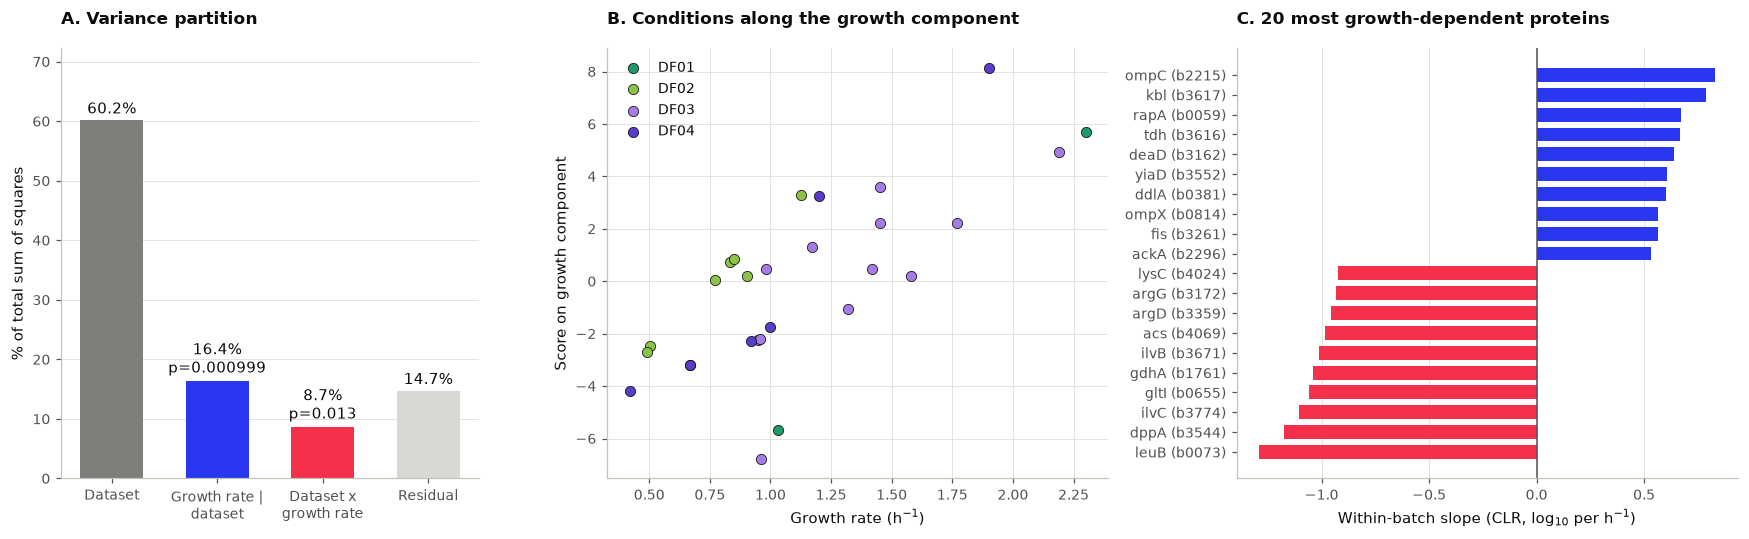

In [58]:
# --- edit here ---
FIGSIZE = (16, 5)
TOP_N = 20                      # proteins shown in panel C (half up, half down)
# ------------------
unit = "CLR, log$_{10}$" if cfg["asca"].get("transform") == "clr" else "log$_{10}$ mass fraction"
term_colour = {"Dataset": "#7f7e79", "Growth rate | dataset": STYLE["up"],
               "Dataset x growth rate": STYLE["down"], "Residual": "#d9d8d2"}
fig, (a, b, c) = plt.subplots(1, 3, figsize=FIGSIZE, gridspec_kw={"width_ratios": [1, 1.2, 1.2]})
vt = variance.drop(index="Total (centred)")
bars = a.bar([t.replace(" | ", " |\n").replace(" x ", " x\n") for t in vt.index], vt["SS_fraction"] * 100,
             color=[term_colour.get(t, STYLE["neutral"]) for t in vt.index], width=0.6)
a.bar_label(bars, labels=[f"{v:.1f}%" + (f"\np={p:.3g}" if pd.notna(p) else "")
                          for v, p in zip(vt["SS_fraction"] * 100, vt["p_permutation"])], padding=2)
a.set_ylabel("% of total sum of squares"); a.set_title("A. Variance partition"); a.grid(axis="x", visible=False)
a.set_ylim(0, vt["SS_fraction"].max() * 120)
sc = asca_scores.copy()
if "Dataset_Source" not in sc:
    sc["Dataset_Source"] = conditions.loc[sc.index, "Dataset_Source"]
scatter_datasets(b, sc[GROWTH], sc["effect_plus_residual_score"], sc["Dataset_Source"])
b.set_xlabel(GROWTH_LABEL); b.set_ylabel("Score on growth component"); b.set_title("B. Conditions along the growth component")
b.legend()
extreme = pd.concat([proteins.head(TOP_N - TOP_N // 2), proteins.tail(TOP_N // 2)])
v = extreme["slope_log_per_h-1"]
c.barh([f"{g} ({i})" for g, i in zip(extreme["gene"].astype(str), extreme.index)], v,
       color=[STYLE["up"] if x > 0 else STYLE["down"] for x in v], height=0.7)
c.invert_yaxis(); c.axvline(0, color="#52514e", linewidth=1); c.grid(axis="y", visible=False)
c.set_xlabel(f"Within-batch slope ({unit} per h$^{{-1}}$)"); c.set_title(f"C. {TOP_N} most growth-dependent proteins")
fig.tight_layout()
save(fig, "F11_asca"); plt.show()

saved: results\figures\final\F11_asca.png


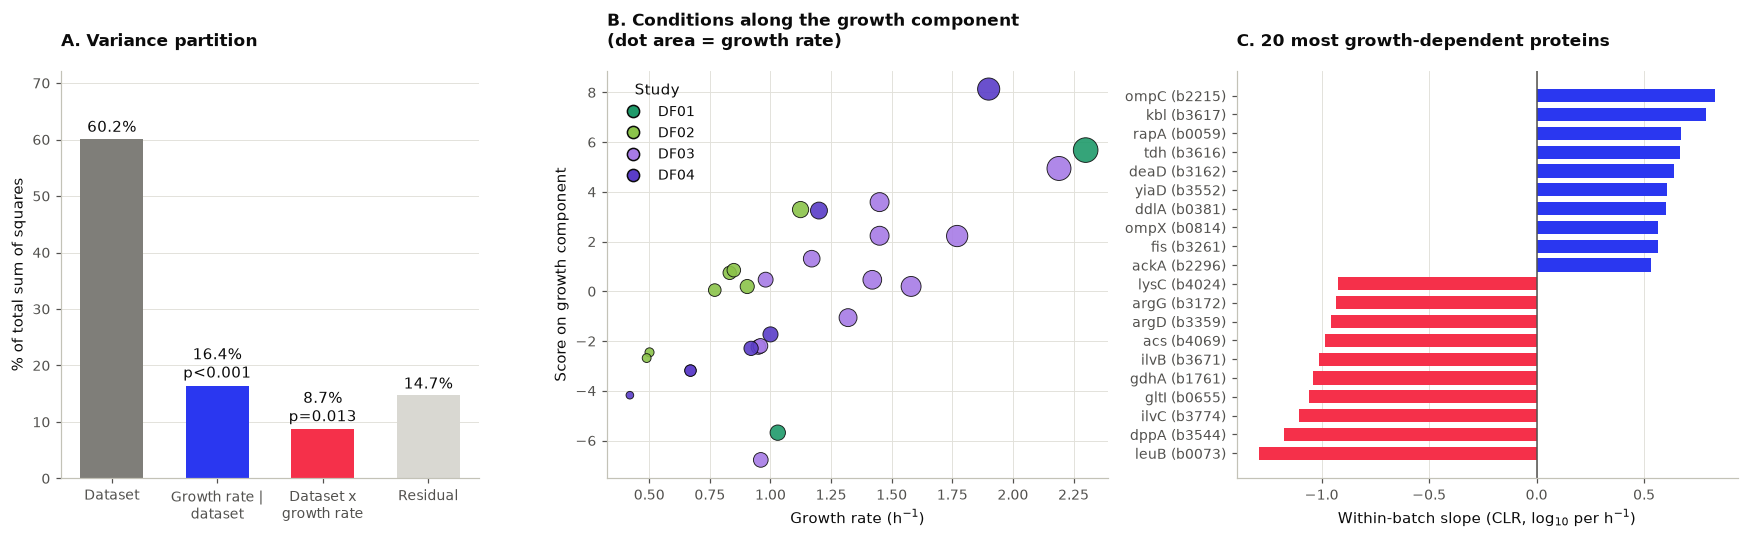

,df,SS,% of total,% after removing dataset,mean square (SS/df),permutation p
Dataset,5,1100.1,60.2,NaN,220.02,
Growth rate | dataset,1,299.8,16.4,41.2,299.76,<0.001
Dataset x growth rate,5,158.6,8.7,21.8,31.72,0.013
Residual,16,269.3,14.7,37.0,16.83,
Total (centred),27,1827.8,100.0,NaN,67.70,


In [61]:
# --- edit here ---
FIGSIZE = (16, 5)
TOP_N = 20                      # proteins shown in panel C (half up, half down)
SIZE_RANGE = (25, 260)          # same as F09: marker area for the slowest / fastest condition
# ------------------
unit = "CLR, log$_{10}$" if cfg["asca"].get("transform") == "clr" else "log$_{10}$ mass fraction"
term_colour = {"Dataset": "#7f7e79", "Growth rate | dataset": STYLE["up"],
               "Dataset x growth rate": STYLE["down"], "Residual": "#d9d8d2"}
fig, (a, b, c) = plt.subplots(1, 3, figsize=FIGSIZE, gridspec_kw={"width_ratios": [1, 1.2, 1.2]})

# ---- A. variance partition --------------------------------------------------
vt = variance.drop(index="Total (centred)")
bars = a.bar([t.replace(" | ", " |\n").replace(" x ", " x\n") for t in vt.index], vt["SS_fraction"] * 100,
             color=[term_colour.get(t, STYLE["neutral"]) for t in vt.index], width=0.6)
a.bar_label(bars, labels=[f"{v:.1f}%" + (("\np<0.001" if p < 0.001 else f"\np={p:.3f}") if pd.notna(p) else "")
                          for v, p in zip(vt["SS_fraction"] * 100, vt["p_permutation"])], padding=2)
a.set_ylabel("% of total sum of squares"); a.set_title("A. Variance partition"); a.grid(axis="x", visible=False)
a.set_ylim(0, vt["SS_fraction"].max() * 120)

# ---- B. conditions along the growth component (dot area = growth rate) ------
sc = asca_scores.copy()
if "Dataset_Source" not in sc:
    sc["Dataset_Source"] = conditions.loc[sc.index, "Dataset_Source"]
lo, hi = sc[GROWTH].min(), sc[GROWTH].max()
size = SIZE_RANGE[0] + (sc[GROWTH] - lo) / (hi - lo) * (SIZE_RANGE[1] - SIZE_RANGE[0])
studies = study_order(sc["Dataset_Source"])
for d in studies:
    m = sc["Dataset_Source"] == d
    b.scatter(sc.loc[m, GROWTH], sc.loc[m, "effect_plus_residual_score"], s=size[m], color=colour(d),
              marker=marker(d), edgecolor=STYLE["edge_colour"], linewidth=0.6, alpha=0.9, zorder=3)
handles = [plt.Line2D([], [], linestyle="", marker=marker(d), markersize=8, markerfacecolor=colour(d),
                      markeredgecolor=STYLE["edge_colour"]) for d in studies]
b.legend(handles, [label(d) for d in studies], title="Study")
b.set_xlabel(GROWTH_LABEL); b.set_ylabel("Score on growth component")
b.set_title("B. Conditions along the growth component\n(dot area = growth rate)")

# ---- C. most growth-dependent proteins ---------------------------------------
extreme = pd.concat([proteins.head(TOP_N - TOP_N // 2), proteins.tail(TOP_N // 2)])
v = extreme["slope_log_per_h-1"]
c.barh([f"{g} ({i})" for g, i in zip(extreme["gene"].astype(str), extreme.index)], v,
       color=[STYLE["up"] if x > 0 else STYLE["down"] for x in v], height=0.7)
c.invert_yaxis(); c.axvline(0, color="#52514e", linewidth=1); c.grid(axis="y", visible=False)
c.set_xlabel(f"Within-batch slope ({unit} per h$^{{-1}}$)"); c.set_title(f"C. {TOP_N} most growth-dependent proteins")

fig.tight_layout()
save(fig, "F11_asca"); plt.show()

# ---- variance partition as a table (for the slide / report) -----------------
within_total = variance.loc["Total (centred)", "SS"] - variance.loc["Dataset", "SS"]
variance_table = pd.DataFrame({
    "df": variance["df"].astype(int),
    "SS": variance["SS"].round(1),
    "% of total": (variance["SS_fraction"] * 100).round(1),
    "% after removing dataset": (variance["SS"] / within_total * 100).where(variance.index != "Dataset").round(1),
    "mean square (SS/df)": (variance["SS"] / variance["df"]).round(2),
    "permutation p": variance["p_permutation"].map(lambda p: "" if pd.isna(p) else ("<0.001" if p < 0.001 else f"{p:.3f}")),
})
variance_table.loc["Total (centred)", "% after removing dataset"] = np.nan
variance_table.to_csv(OUT / "F11_asca_variance_table.tsv", sep="\t")
variance_table

## F12 · Prediction of growth rate in a held-out study

saved: results\figures\final\F12_prediction.png


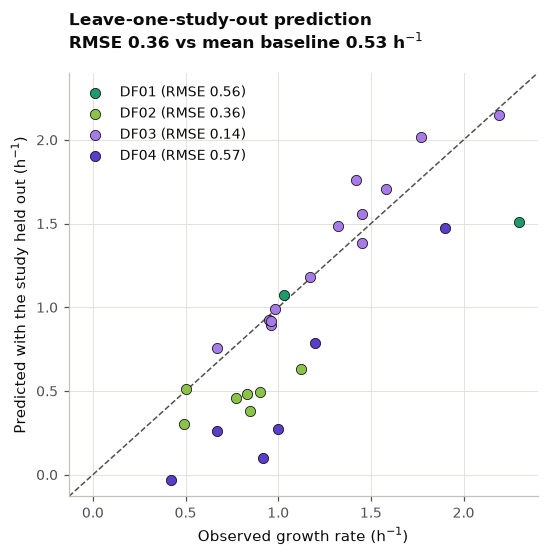

In [60]:
# --- edit here ---
FIGSIZE = (5.5, 5)
LIMITS = None                   # e.g. (-0.3, 2.5)
# ------------------
pr = predictions
rmse = pr.groupby("Dataset_Source").apply(lambda g: float(np.sqrt(np.mean((g["observed"] - g["predicted"]) ** 2))))
fig, ax = plt.subplots(figsize=FIGSIZE)
for d in study_order(pr["Dataset_Source"]):
    g = pr[pr["Dataset_Source"] == d]
    ax.scatter(g["observed"], g["predicted"], s=STYLE["marker_size"], color=colour(d), marker=marker(d),
               edgecolor=STYLE["edge_colour"], linewidth=0.5, zorder=3, label=f"{label(d)} (RMSE {rmse[d]:.2f})")
lim = LIMITS or (min(pr["observed"].min(), pr["predicted"].min()) - 0.1, max(pr["observed"].max(), pr["predicted"].max()) + 0.1)
ax.plot(lim, lim, color="#52514e", linestyle="--", linewidth=1, zorder=1)
ax.set_xlim(lim); ax.set_ylim(lim)
pooled = float(np.sqrt(np.mean((pr["observed"] - pr["predicted"]) ** 2)))
base = float(np.sqrt(np.mean((pr["observed"] - pr["baseline_prediction"]) ** 2)))
ax.set_xlabel("Observed growth rate (h$^{-1}$)"); ax.set_ylabel("Predicted with the study held out (h$^{-1}$)")
ax.set_title(f"Leave-one-study-out prediction\nRMSE {pooled:.2f} vs mean baseline {base:.2f} h$^{{-1}}$")
ax.legend(loc="upper left")
save(fig, "F12_prediction"); plt.show()

## F13 · Sensitivity of COG slopes to the treatment of censored values

saved: results\figures\final\F13_sensitivity_censoring.png


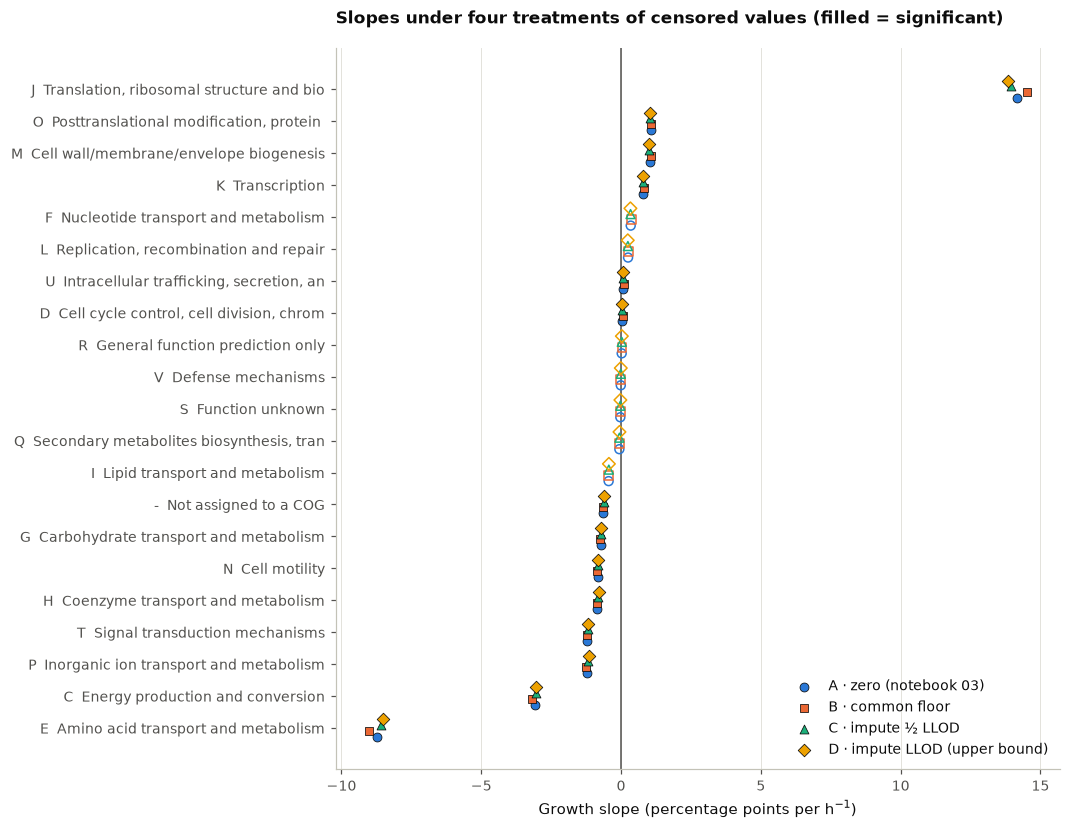

In [16]:
# --- edit here ---
FIGSIZE = None
# ------------------
scenarios = [c for c in sensitivity.columns if not c.endswith(" significant")]
order = sensitivity[scenarios[0]].sort_values().index
fig, ax = plt.subplots(figsize=FIGSIZE or (8.5, 0.32 * len(order) + 1.8))
offsets = np.linspace(-0.27, 0.27, len(scenarios))
shapes = ["o", "s", "^", "D", "v"]
for k, (off, name) in enumerate(zip(offsets, scenarios)):
    filled = sensitivity.loc[order, name + " significant"].astype(bool).to_numpy()
    y = np.arange(len(order)) + off
    x = sensitivity.loc[order, name].to_numpy()
    c = STYLE["series"][k % len(STYLE["series"])]
    ax.scatter(x[filled], y[filled], color=c, marker=shapes[k % 5], s=34, edgecolor=STYLE["edge_colour"],
               linewidth=0.5, label=name, zorder=3)
    ax.scatter(x[~filled], y[~filled], facecolors="none", edgecolors=c, marker=shapes[k % 5], s=34, zorder=3)
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_yticks(range(len(order)), [f"{c}  {labels.get(c, '')[:40]}" for c in order]); ax.grid(axis="y", visible=False)
ax.set_xlabel("Growth slope (percentage points per h$^{-1}$)")
ax.set_title("Slopes under four treatments of censored values (filled = significant)")
ax.legend(loc="lower right")
save(fig, "F13_sensitivity_censoring"); plt.show()

## F14 · Permutation null distributions (optional)

Drawn only if notebooks 04 and 05 saved their null distributions (`04_asca_null_distribution.tsv`, `05_prediction_null_rmse.tsv`).

To save them, add one line at the end of the last cell of each notebook and re-run it once:

* notebook 04: `pd.Series(result.null_distribution, name="SS_growth_null").to_csv(cfg.tables / "04_asca_null_distribution.tsv", sep="\t")`
* notebook 05: `pd.Series(result["null_rmse"], name="rmse_null").to_csv(cfg.tables / "05_prediction_null_rmse.tsv", sep="\t")`

In [17]:
# --- edit here ---
FIGSIZE = (11, 3.8)
# ------------------
if null_asca is None or null_pls is None:
    print("Null distributions not saved yet: add the one-line saves to notebooks 04 and 05 (see the text above).")
else:
    fig, (a, b) = plt.subplots(1, 2, figsize=FIGSIZE)
    a.hist(null_asca.iloc[:, 0], bins=40, color="#d9d8d2")
    a.axvline(variance.loc["Growth rate | dataset", "SS"], color=STYLE["up"], linewidth=STYLE["line_width"])
    a.set_xlabel("SS(growth | study), within-study permutations"); a.set_title("A. ASCA growth effect")
    pooled = float(np.sqrt(np.mean((predictions["observed"] - predictions["predicted"]) ** 2)))
    b.hist(null_pls.iloc[:, 0], bins=30, color="#d9d8d2")
    b.axvline(pooled, color=STYLE["up"], linewidth=STYLE["line_width"])
    b.set_xlabel("Pooled RMSE with permuted growth rates (h$^{-1}$)"); b.set_title("B. Prediction")
    fig.tight_layout()
    save(fig, "F14_permutation_nulls"); plt.show()

Null distributions not saved yet: add the one-line saves to notebooks 04 and 05 (see the text above).


saved: results\figures\final\F12b_prediction_errors_pr.png


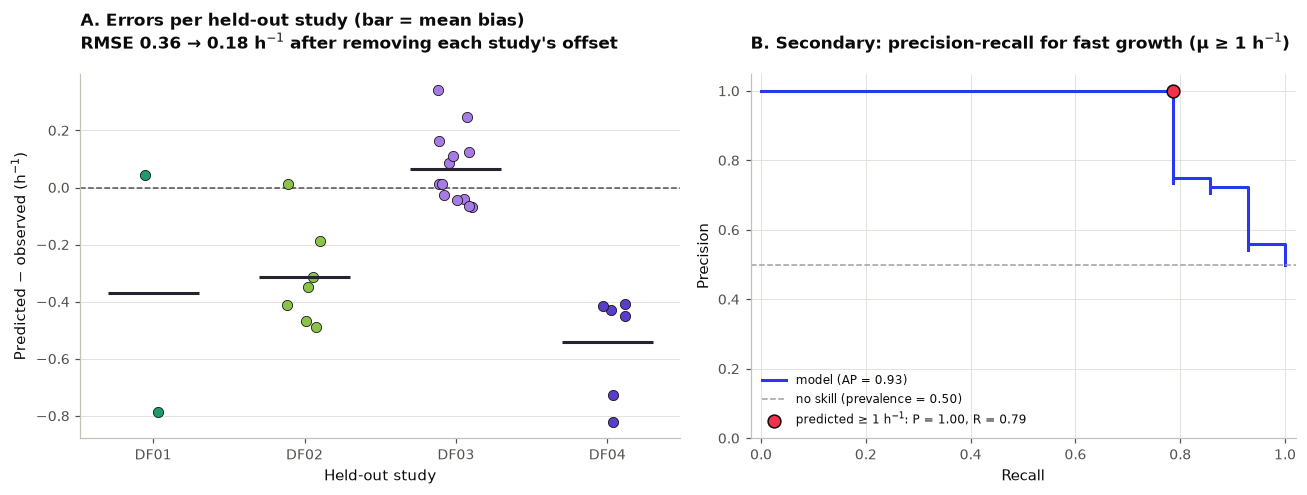

precision-recall: AP 0.93 (prevalence 0.50); at the 1 h-1 cut: TP 11, FP 0, FN 3


,n,RMSE,RMSE_mean_baseline,bias (mean error),SD of error,Spearman (ranking),% of MSE from bias
held_out,,,,,,,
DF01,2.0,0.558,0.854,-0.371,0.417,NaN,44.254
DF02,7.0,0.355,0.515,-0.315,0.164,0.536,78.748
DF03,13.0,0.139,0.498,0.066,0.123,0.930,22.275
DF04,6.0,0.567,0.488,-0.542,0.167,0.943,91.305
All (pooled),28.0,0.363,0.534,-0.191,0.309,0.857,27.660


In [62]:
# --- edit here ---
FIGSIZE = (12, 4.6)
FAST = 1.0                      # h-1: "fast growth" threshold for the secondary precision-recall analysis
# ------------------
from scipy.stats import spearmanr
from sklearn.metrics import precision_recall_curve, average_precision_score

pr = predictions.copy()
pr["error"] = pr["predicted"] - pr["observed"]
studies = study_order(pr["Dataset_Source"])

# ---- 1. where does the RMSE come from? bias (offset) vs scatter, per held-out study
rows = []
for d in studies:
    g = pr[pr["Dataset_Source"] == d]
    rows.append({"held_out": label(d), "n": len(g),
                 "RMSE": np.sqrt(np.mean(g["error"] ** 2)),
                 "RMSE_mean_baseline": np.sqrt(np.mean((g["baseline_prediction"] - g["observed"]) ** 2)),
                 "bias (mean error)": g["error"].mean(),
                 "SD of error": g["error"].std(ddof=0),
                 "Spearman (ranking)": spearmanr(g["observed"], g["predicted"])[0] if len(g) > 2 else np.nan})
error_table = pd.DataFrame(rows).set_index("held_out")
# RMSE² = bias² + SD²  -> how much of each study's squared error is a constant offset
error_table["% of MSE from bias"] = 100 * error_table["bias (mean error)"] ** 2 / error_table["RMSE"] ** 2
pooled = np.sqrt(np.mean(pr["error"] ** 2))
debiased = np.sqrt(np.mean((pr["error"] - pr.groupby("Dataset_Source")["error"].transform("mean")) ** 2))

fig, (a, b) = plt.subplots(1, 2, figsize=FIGSIZE, gridspec_kw={"width_ratios": [1.1, 1]})
rng = np.random.default_rng(0)
for i, d in enumerate(studies):
    g = pr[pr["Dataset_Source"] == d]
    a.scatter(i + rng.uniform(-0.12, 0.12, len(g)), g["error"], s=STYLE["marker_size"], color=colour(d),
              marker=marker(d), edgecolor=STYLE["edge_colour"], linewidth=0.5, zorder=3)
    a.hlines(g["error"].mean(), i - 0.3, i + 0.3, color="#26232e", linewidth=2, zorder=4)
a.axhline(0, color="#52514e", linestyle="--", linewidth=1)
a.set_xticks(range(len(studies)), [label(d) for d in studies]); a.grid(axis="x", visible=False)
a.set_xlabel("Held-out study"); a.set_ylabel("Predicted − observed (h$^{-1}$)")
a.set_title(f"A. Errors per held-out study (bar = mean bias)\n"
            f"RMSE {pooled:.2f} → {debiased:.2f} h$^{{-1}}$ after removing each study's offset")

# ---- 2. secondary: precision-recall for "fast growth" (observed >= FAST) --------
y = (pr["observed"] >= FAST).astype(int).to_numpy()
precision, recall, _ = precision_recall_curve(y, pr["predicted"])
ap = average_precision_score(y, pr["predicted"])
b.step(recall, precision, where="post", color=STYLE["up"], linewidth=STYLE["line_width"], label=f"model (AP = {ap:.2f})")
b.axhline(y.mean(), color=STYLE["neutral"], linestyle="--", linewidth=1, label=f"no skill (prevalence = {y.mean():.2f})")
called = pr["predicted"].to_numpy() >= FAST
tp, fp, fn = int((called & (y == 1)).sum()), int((called & (y == 0)).sum()), int((~called & (y == 1)).sum())
p_at = tp / (tp + fp) if tp + fp else np.nan
r_at = tp / (tp + fn) if tp + fn else np.nan
b.scatter([r_at], [p_at], s=70, color=STYLE["down"], edgecolor=STYLE["edge_colour"], zorder=4,
          label=f"predicted ≥ {FAST:g} h$^{{-1}}$: P = {p_at:.2f}, R = {r_at:.2f}")
b.set_xlim(-0.02, 1.02); b.set_ylim(0, 1.05)
b.set_xlabel("Recall"); b.set_ylabel("Precision")
b.set_title(f"B. Secondary: precision-recall for fast growth (μ ≥ {FAST:g} h$^{{-1}}$)")
b.legend(loc="lower left", fontsize=8)
fig.tight_layout()
save(fig, "F12b_prediction_errors_pr"); plt.show()

error_table.loc["All (pooled)"] = [len(pr), pooled, np.sqrt(np.mean((pr["baseline_prediction"] - pr["observed"]) ** 2)),
                                   pr["error"].mean(), pr["error"].std(ddof=0),
                                   spearmanr(pr["observed"], pr["predicted"])[0], 100 * pr["error"].mean() ** 2 / pooled ** 2]
error_table = error_table.round(3)
error_table.to_csv(OUT / "F12b_prediction_error_table.tsv", sep="\t")
print(f"precision-recall: AP {ap:.2f} (prevalence {y.mean():.2f}); at the {FAST:g} h-1 cut: TP {tp}, FP {fp}, FN {fn}")
error_table